# EDA (Exploratory Data Analysis)
Thực hành trên bộ dữ liệu về xe hơi

## 1. Hiểu tổng quan về bộ dữ liệu


*EDA = mô tả + trực quan để lấy insight; chưa suy nhân quả, chưa huấn luyện mô hình.*

### 1.1. Đọc dữ liệu từ file csv và hiển thị 5 dòng dữ liệu đầu tiên.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df= pd.read_csv("dataCAR.csv")
df.head()

,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Market Category,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP
0,BMW,1 Series M,2011,premium unleaded (required),335.0,6.0,MANUAL,rear wheel drive,2.0,"Factory Tuner,Luxury,High-Performance",Compact,Coupe,26,19,3916,46135
1,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Convertible,28,19,3916,40650
2,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,High-Performance",Compact,Coupe,28,20,3916,36350
3,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Coupe,28,18,3916,29450
4,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Luxury,Compact,Convertible,28,18,3916,34500


### 1.2. Hiển thị 5 dòng dữ liệu cuối cùng

In [4]:
df.tail()

,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Market Category,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP
11909,Acura,ZDX,2012,premium unleaded (required),300.0,6.0,AUTOMATIC,all wheel drive,4.0,"Crossover,Hatchback,Luxury",Midsize,4dr Hatchback,23,16,204,46120
11910,Acura,ZDX,2012,premium unleaded (required),300.0,6.0,AUTOMATIC,all wheel drive,4.0,"Crossover,Hatchback,Luxury",Midsize,4dr Hatchback,23,16,204,56670
11911,Acura,ZDX,2012,premium unleaded (required),300.0,6.0,AUTOMATIC,all wheel drive,4.0,"Crossover,Hatchback,Luxury",Midsize,4dr Hatchback,23,16,204,50620
11912,Acura,ZDX,2013,premium unleaded (recommended),300.0,6.0,AUTOMATIC,all wheel drive,4.0,"Crossover,Hatchback,Luxury",Midsize,4dr Hatchback,23,16,204,50920
11913,Lincoln,Zephyr,2006,regular unleaded,221.0,6.0,AUTOMATIC,front wheel drive,4.0,Luxury,Midsize,Sedan,26,17,61,28995


### 1.3. Hiển thị kiểu dữ liệu của từng cột

In [5]:
df.dtypes

Make                     str
Model                    str
Year                   int64
Engine Fuel Type         str
Engine HP            float64
Engine Cylinders     float64
Transmission Type        str
Driven_Wheels            str
Number of Doors      float64
Market Category          str
Vehicle Size             str
Vehicle Style            str
highway MPG            int64
city mpg               int64
Popularity             int64
MSRP                   int64
dtype: object

#### Câu hỏi ôn tập: Định nghĩa mục tiêu & nạp dữ liệu (Stage 1)

**Câu 1 (Tự luận):** Viết 3 ý: (1) bạn muốn biết gì từ dữ liệu xe, (2) kết quả phục vụ ai, (3) thế nào là phân tích “đủ tốt” ở bước EDA (ví dụ: mô tả được giá, thấy quan hệ HP–Price…).

**Câu 2 (Trắc nghiệm):** Câu nào **SAI**?
- A. Chồng thêm dòng khi hai bảng **cùng cột** (ví dụ xe năm này + năm kia)
- B. Ghép hai bảng **theo khóa** (ví dụ hồ sơ xe + bảng giá theo mẫu)
- C. Đọc CSV và đọc Excel đều là nạp **một** bảng
- D. Hai cách ghép bảng ở A và B **luôn** cho ra kết quả giống nhau, không cần phân biệt

**Câu 3 (Trắc nghiệm):** Trước khi EDA, dữ liệu dạng bảng (mỗi dòng là một quan sát, mỗi cột là một biến) được **nhập** vào pandas thành DataFrame. Câu nào **đúng**?
- A. Chỉ định dạng CSV mới đọc được thành DataFrame
- B. Có thể nhập từ nhiều định dạng và nguồn: CSV (`read_csv`), Excel (`read_excel`), hoặc bảng lấy từ kho dữ liệu (Kaggle Hub, cơ sở dữ liệu…) rồi đọc thành DataFrame. Định dạng và nguồn khác nhau; thao tác nhập thì cùng mục đích
- C. Định dạng Excel không dùng được trong EDA
- D. Phải ghép bảng (`merge`) trước thì mới đọc được tệp CSV


In [6]:
cau_1 = """
(1) muốn biết gì từ dữ liệu xe: phân tích các yếu tố ảnh hưởng đến giá xe, vd: công suất động cơ (HP), 
năm sản xuất, mức tiêu thụ nhiên liệu và thương hiệu
(2) kết quả phục vụ ai: phục vụ người mua xe, người bán xe, 
doanh nghiệp kinh doanh ô tô trong việc tham khảo và định giá xe
(3) phân tích đủ tốt ở bước EDA: khi đã mô tả được đặc điểm dữ liệu, 
kiểm tra dữ liệu thiếu/trùng và phát hiện được các mối quan hệ đáng chú ý, 
ví dụ HP có quan hệ với Price
"""
cau_2 = "D"
cau_3 = "B"

## 2. Tiền xử lý dữ liệu

### 2.1. Xóa đi các cột không quan tâm
Hãy xóa các cột: 'Engine Fuel Type', 'Market Category', 'Vehicle Style', 'Popularity', 'Number of Doors', 'Vehicle Size'
Sau đó, hiển thị lại 5 dòng dữ liệu đầu tiên

In [7]:
df = df.drop(columns=['Engine Fuel Type', 'Market Category', 'Vehicle Style','Popularity', 'Number of Doors', 'Vehicle Size'])
df.head()

,Make,Model,Year,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,highway MPG,city mpg,MSRP
0,BMW,1 Series M,2011,335.0,6.0,MANUAL,rear wheel drive,26,19,46135
1,BMW,1 Series,2011,300.0,6.0,MANUAL,rear wheel drive,28,19,40650
2,BMW,1 Series,2011,300.0,6.0,MANUAL,rear wheel drive,28,20,36350
3,BMW,1 Series,2011,230.0,6.0,MANUAL,rear wheel drive,28,18,29450
4,BMW,1 Series,2011,230.0,6.0,MANUAL,rear wheel drive,28,18,34500


### 2.2. Đổi tên các cột để ngắn gọn hơn

Đổi tên các cột như sau:

"Engine HP": "HP",

"Engine Cylinders": "Cylinders",

"Transmission Type": "Transmission",

"Driven_Wheels": "Drive Mode",

"highway MPG": "MPG-H",

"city mpg": "MPG-C",

"MSRP": "Price"

Sau đó, hiển thị lại 5 dòng dữ liệu đầu tiên

In [8]:
df = df.rename(columns = {"Engine HP": "HP", "Engine Cylinders": "Cylinders", "Transmission Type": "Transmission", "Driven_Wheels": "Drive Mode", "highway MPG": "Highway MPG", "city mpg": "City MPG", "MSRP": "Price"})
df.head()

,Make,Model,Year,HP,Cylinders,Transmission,Drive Mode,Highway MPG,City MPG,Price
0,BMW,1 Series M,2011,335.0,6.0,MANUAL,rear wheel drive,26,19,46135
1,BMW,1 Series,2011,300.0,6.0,MANUAL,rear wheel drive,28,19,40650
2,BMW,1 Series,2011,300.0,6.0,MANUAL,rear wheel drive,28,20,36350
3,BMW,1 Series,2011,230.0,6.0,MANUAL,rear wheel drive,28,18,29450
4,BMW,1 Series,2011,230.0,6.0,MANUAL,rear wheel drive,28,18,34500


#### Câu hỏi ôn tập: Data Wrangling (Stage 1)

Pipeline: **Discovery → Structuring → Cleaning → Enriching → Validating → Publishing**

**Câu 1 (Trắc nghiệm):** Xóa cột không dùng và đổi tên (`Engine HP` → `HP`) thuộc bước nào?
- A. Discovery
- B. Structuring
- C. Enriching
- D. Publishing

**Câu 2:** Kéo mỗi việc vào đúng bước (viết Discovery / Structuring / Cleaning / Enriching / Validating / Publishing):
- xem `head`, hiểu ý nghĩa cột
- đổi tên cột, bỏ cột thừa
- xử lý trùng, ô trống, giá trị lỗi
- tạo biến mới (ví dụ tuổi xe từ `Year`)
- kiểm tra lại `shape`, missing, biểu đồ
- xuất bảng sạch để dùng tiếp

**Câu 3 (Tự luận):** Vì sao nên chuẩn hóa tên cột trước khi vẽ / thống kê? Rủi ro nếu báo cáo dùng tên cũ trong khi bảng đã đổi tên?

In [9]:
cau_1 = "B" 
cau_2 = """ 
- xem `head`, hiểu ý nghĩa cột -> Discovery
- đổi tên cột, bỏ cột thừa -> Structuring
- xử lý trùng, ô trống, giá trị lỗi -> Cleaning
- tạo biến mới (ví dụ tuổi xe từ `Year`) -> Enriching
- kiểm tra lại `shape`, missing, biểu đồ -> Validating
- xuất bảng sạch để dùng tiếp -> Publishing
"""
cau_3 = """ 
- Chuẩn hóa tên cột giúp dữ liệu nhất quán, dễ sử dụng trong thống kê và trực quan hóa, giảm lỗi khi viết code. 
- Nếu báo cáo vẫn sử dụng tên cột cũ sau khi dữ liệu đã đổi tên, 
người đọc dễ nhầm lẫn và việc kiểm tra hoặc tái sử dụng code sẽ khó khăn
"""

### 2.3. Xử lý dữ liệu trùng lặp

#### Hiển thị số dòng và số cột của bảng dữ liệu

In [10]:
df.shape

(11914, 10)

#### Hiển thị các dòng dữ liệu bị trùng

In [11]:
df.duplicated()

0        False
1        False
2        False
3        False
4        False
         ...  
11909    False
11910    False
11911    False
11912    False
11913    False
Length: 11914, dtype: bool

#### Hiển thị số lượng giá trị phân biệt (khác nhau đôi một) của từng cột dữ liệu

In [12]:
df.nunique()

Make              48
Model            915
Year              28
HP               356
Cylinders          9
Transmission       5
Drive Mode         4
Highway MPG       59
City MPG          69
Price           6049
dtype: int64

#### Xóa đi những dữ liệu bị trùng lặp

**Câu hỏi gợi ý:**
1. Vì sao cần xóa dòng trùng trước khi phân tích / mô hình hóa? Nếu giữ nguyên, các chỉ số như trung bình `Price`, tần suất `Make` sẽ bị ảnh hưởng thế nào?
2. Khi xóa trùng, mặc định nên giữ dòng nào: dòng đầu, dòng cuối, hay xóa hết các bản sao? Khi nào nên đổi cách giữ?
3. Có phải mọi xe cùng `Make`, `Year`, `HP` đều là dữ liệu lỗi? Khi nào nên xét trùng theo **toàn bộ dòng**, khi nào nên xét trùng theo **một số cột**?

In [13]:
df = df.drop_duplicates()

In [14]:
cau_1 = """
- vì nếu giữ dữ liệu trùng, một quan sát có thể bị tính nhiều lần, làm kết quả phân tích bị lệch
- Nếu giữ nguyên, trung bình Price có thể tăng hoặc giảm tùy giá trị bị lặp,
còn tần suất Make có thể khiến một hãng xe xuất hiện phổ biến hơn thực tế. 
Ngoài ra, dữ liệu trùng có thể khiến mô hình học lệch và làm kết quả đánh giá thiếu chính xác."""
cau_2 = """
- Mặc định nên giữ dòng đầu tiên (keep='first'). 
- Chỉ đổi sang giữ dòng cuối hoặc xóa tất cả bản sao khi dựa vào thời gian cập nhật 
hoặc chất lượng dữ liệu để xác định dòng nào cần giữ
"""
cau_3 = """
Không. Các xe cùng Make, Year, HP chưa chắc bị trùng vì có thể khác Model, Price, phiên bản,...
- Trùng toàn bộ dòng -> dùng khi muốn tìm các dòng giống hệt nhau.
- Trùng một số cột -> dùng khi các cột đó được xác định là khóa/tiêu chí nhận diện bản ghi.
"""

#### Xử lý dữ liệu trùng lặp

**Câu 1 (Trắc nghiệm):** Hàm `df.drop_duplicates()` mặc định sẽ làm gì?
- A. Xóa tất cả các dòng xuất hiện nhiều hơn một lần, không giữ lại dòng nào
- B. Giữ lại dòng trùng **đầu tiên** (`keep='first'`), xóa các dòng giống hẹt phía sau
- C. Giữ lại dòng trùng **cuối cùng** (`keep='last'`)
- D. Chỉ đánh dấu trùng, không xóa dòng nào

**Câu 2 (Trắc nghiệm):** Sau khi xóa trùng, `nunique()` của từng cột thường thay đổi như thế nào?
- A. Giảm vì mỗi giá trị phân biệt bị xóa hết
- B. Tăng vì bảng dữ liệu có thêm cột mới
- C. Không đổi (hoặc gần như không đổi): số giá trị khác nhau vẫn giữ, chỉ giảm số dòng lặp
- D. Luôn bằng 0 vì dữ liệu đã bị làm sạch

**Câu 3 (Tự luận ngắn):** Giả sử hai dòng xe có cùng `Make`, `Year`, `HP`, `Cylinders` nhưng **khác `Price`**. Đó có phải là dòng trùng cần xóa bằng `drop_duplicates()` không? Nếu dùng `drop_duplicates(subset=['Make','Year','HP'])` thì rủi ro là gì đối với phân tích giá xe?

**Câu 4 (Tự luận phản biện):** Trên tập car, nhiều dòng trùng có thể là **cùng một mẫu xe được ghi hai lần** (lỗi thu thập), hoặc là **hai xe giống cấu hình thật**. Theo bạn, với mục tiêu EDA và dự đoán `Price`, nên xóa trùng toàn cục hay giữ lại? Hãy nêu **một lợi ích** và **một rủi ro** của việc xóa.

In [15]:
cau_1 = "B"
cau_2 = "C"
cau_3 = """
không. Vì Price khác nhau nên hai dòng không giống hệt nhau, drop_duplicates() không xóa chúng.
Nếu dùng subset=['Make','Year','HP'], có thể xóa nhầm một xe có giá khác, làm sai phân tích giá
"""
cau_4 = """
Nên kiểm tra ý nghĩa dữ liệu trước khi xóa.
-Lợi ích: Xóa dữ liệu trùng thật giúp tránh một mẫu xe bị tính nhiều lần, giảm sai lệch kết quả.
-Rủi ro: Có thể xóa nhầm những xe giống cấu hình nhưng thực sự là các xe khác nhau, làm mất dữ liệu và ảnh hưởng mô hình dự đoán Price.
"""

#### Hiển thị lại số lượng giá trị phân biệt (khác nhau đôi một) của từng cột dữ liệu

In [16]:
df.nunique()

Make              48
Model            915
Year              28
HP               356
Cylinders          9
Transmission       5
Drive Mode         4
Highway MPG       59
City MPG          69
Price           6049
dtype: int64

### 2.4. Xử lý dữ liệu rỗng

1. Ô trống xuất hiện vì sao: ngẫu nhiên hoàn toàn, phụ thuộc cột khác đã thấy, hay phụ thuộc chính giá trị bị giấu?
2. Cột **số**, ít trống, **không phải** biến cần dự đoán, phân phối lệch: nên điền trung bình hay trung vị?
3. Cột **chữ / nhãn**: nên điền thế nào?
4. Khi nào nên **bỏ dòng** (thiếu biến mục tiêu, giá trị không hợp lệ, quá nhiều dòng trống) thay vì điền? Sau khi bỏ dòng, chỉ số dòng có thể lệch — bạn xử lý ra sao?
5. Nhiều ô “không muốn nêu”: gán nhãn riêng hay thay bằng giá trị phổ biến nhất?

In [17]:
cau_1 = """ 
có thể do: ngẫu nhiên hoàn toàn, phụ thuộc vào cột khác, phụ thuộc chính giá trị bị thiếu
"""
cau_2 = """ 
nên điền trung vị vì ít bị ảnh hưởng bởi giá trị ngoại lai
"""
cau_3 = """
thường điền bằng giá trị xuất hiện nhiều nhất hoặc tạo 1 nhãn riêng
"""
cau_4 = """
- nên bỏ khi: thiếu biến mục tiêu, giá trị ko hợp lệ, 1 dòng có quá nhiều ô trống như Unkhown.
Tuy nhiên, không nên xóa tự động mọi dòng có ô trống; cần xem mức độ thiếu và nguy cơ làm lệch dữ liệu.
- sau khi xóa nên df.reset_index(drop=True) để đánh lại chỉ số
"""
cau_5 = """
- nên gán nhãn riêng như Unknown/Not disclosed, không nên tự động thay bằng giá trị phổ biến nhất vì có thể làm sai phân phối dữ liệu
"""

#### Hiển thị số lượng giá trị rỗng của từng cột dữ liệu

In [18]:
df.isnull().sum()

Make             0
Model            0
Year             0
HP              69
Cylinders       30
Transmission     0
Drive Mode       0
Highway MPG      0
City MPG         0
Price            0
dtype: int64

#### Xóa đi các giá trị rỗng, sau đó hiển thị lại số lượng giá trị phân biệt của từng cột.

In [19]:
df = df.dropna()
df.nunique()

Make              47
Model            904
Year              28
HP               355
Cylinders          9
Transmission       5
Drive Mode         4
Highway MPG       44
City MPG          50
Price           6014
dtype: int64

#### Hiển thị lại số lượng giá trị rỗng của từng cột dữ liệu

In [20]:
df.isnull().sum()

Make            0
Model           0
Year            0
HP              0
Cylinders       0
Transmission    0
Drive Mode      0
Highway MPG     0
City MPG        0
Price           0
dtype: int64

#### Câu hỏi ôn tập: Missingness & cách xử lý ô trống (Stage 1)

**Câu 1 (Trắc nghiệm):** Ô trống ở `HP` xuất hiện hoàn toàn ngẫu nhiên (lỗi đường truyền khi cào web), không phụ thuộc thuộc tính xe. Đây là:
- A. MAR
- B. MNAR
- C. MCAR
- D. Không thuộc các cơ chế trên

**Câu 2 (Trắc nghiệm):** `Cylinders` trống chủ yếu ở xe điện vì xe điện không dùng xi-lanh — thiếu **phụ thuộc cột đã quan sát** (loại nhiên liệu / xe điện). Đây là:
- A. MCAR
- B. MAR
- C. MNAR
- D. Cả A và B

**Câu 3 (Tự luận):** MNAR là gì? Ví dụ với `Price` (người bán giấu giá vì xe quá rẻ/quá đắt). Vì sao điền **trung bình** cho `Price` trong trường hợp này làm lệch bản chất dữ liệu?

**Câu 4 (Trắc nghiệm):** Cột số, **ít** trống, **không phải** biến mục tiêu, phân phối **lệch**. Stage 1 gợi ý điền bằng gì?
- A. Trung bình (mean)
- B. Trung vị (median)
- C. Mode của cột chữ
- D. Luôn xóa hết dòng

**Câu 5 (Trắc nghiệm):** Cột chữ / phân loại (`Transmission`, `Make`) thiếu vài ô. Ưu tiên điền:
- A. Mean
- B. Median
- C. Mode 
- D. IQR

**Câu 6 (Trắc nghiệm):** Khi nào nên **xóa dòng** rồi **đặt lại chỉ số dòng**, thay vì điền?
- A. Thiếu biến mục tiêu (`Price`), giá trị không hợp lệ (ví dụ năm = −1), hoặc quá nhiều dòng trống
- B. Chỉ khi thiếu đúng 1 ô số
- C. Khi muốn giữ nguyên mọi dòng bằng mọi giá
- D. Khi biến là phân loại và muốn giữ nhãn đặc biệt

**Câu 7 (Tự luận):** Nhiều ô kiểu “không muốn nêu / Unknown”. Nên gán nhãn **Unknown** hay thay bằng mode? Vì sao mode có thể **giấu** nhóm người từ chối trả lời?

**Câu 8:** Với từng cột còn trống, hãy tự quyết định: điền (mean / median / mode / Unknown) hay xóa dòng. Viết **lý do 1 câu / cột**. Nhớ: `Price` là mục tiêu thì thiếu `Price` thường **không** điền lung tung.

In [ ]:
cau_1 = "C"
cau_2 = "B"
cau_3 = """
MNAR: là khi việc thiếu dữ liệu phụ thuộc vào chính giá trị bị thiếu
Ví dụ người bán giấu Price vì xe quá đắt/rẻ. 
Điền trung bình sẽ làm mất sự khác biệt thực tế và làm sai phân phối giá.
"""
cau_4 = "B"
cau_5 = "C"
cau_6 = "A"
cau_7 = """ 
Nên giữ nhãn Unknown. 
Vì “không muốn nêu” là một thông tin có ý nghĩa; thay bằng mode có thể xóa mất nhóm người này và làm sai phân phối dữ liệu.
"""
cau_8 = """ 
- cột số, phân phối lệch -> median -> vì ít bị ảnh hưởng bởi outlier
- cột số, phân phối tương đối đều -> mean -> vì đại diện tốt cho giá trị trung bình
- cột chữ/phân loại -> mode ->vì đây là giá trị xuất hiện nhiều nhất

- ô có giá trị "không muốn nêu" hoặc "Unknown" -> giữ hoặc gán nhãn Unknown -> vì để không làm mất thông tin
- cột Price là biến mục tiêu, nếu bị thiếu -> xóa dòng -> vì không nên tự điền giá trị mục tiêu
- giá trị không hợp lệ -> xóa dòng -> vì dữ liệu không đáng tin cậy
- dòng có quá nhiều ô trống -> xóa dòng -> vì không đủ thông tin để phân tích
"""

### 2.5. Xử lý outlier

**Câu hỏi gợi ý:**
1. Boxplot cho `Price`, `HP`, `Cylinders` cho thấy gì (trung vị, khoảng giữa, điểm nằm ngoài)?
2. Độ trải giữa (IQR) dùng để xác định ngưỡng thế nào?
3. Ngoài **xóa** điểm lệch, còn **cắt về ngưỡng** và **kéo cực trị vào percentile**. Khác nhau ở chỗ nào (số dòng, giá trị bị đổi)? Khi nào nên xóa, khi nào nên giữ siêu xe?

In [ ]:
cau_1 = """boxplot cho Price, HP, Cylinders
đường giữa hộp là trung vị (Median)
phần hộp từ Q1 đến Q3 là khoảng giữa (IQR), chứa khoảng 50% dữ liệu
các điểm nằm ngoài hộp là các giá trị có khả năng là outlier
"""

cau_2 = """xác định ngưỡng outlier bằng IQR
IQR = Q3 - Q1
ngưỡng dưới = Q1 - 1.5 * IQR
ngưỡng trên = Q3 + 1.5 * IQR
giá trị nằm ngoài hai ngưỡng trên được xem là outlier
"""

cau_3 = """các cách xử lý outlier
- xóa outlier: số dòng giảm, giá trị còn lại không bị thay đổi
dùng khi outlier là lỗi dữ liệu hoặc dữ liệu không đáng tin cậy
- cắt về ngưỡng: số dòng không đổi nhưng giá trị outlier được đưa về ngưỡng
- kéo cực trị về percentile: số dòng không đổi nhưng giá trị cực trị được đưa về giá trị percentile
nếu là siêu xe có giá cao nhưng đó là dữ liệu thực tế thì không nên xóa
có thể giữ lại hoặc dùng clipping/percentile để giảm ảnh hưởng của giá trị cực trị
"""

#### Vẽ boxplot cho cột Price

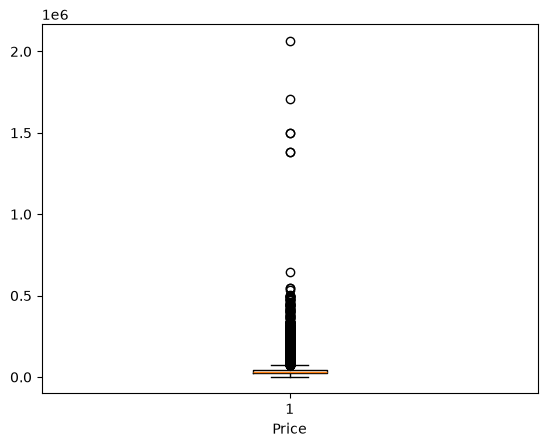

In [23]:
plt.boxplot(df['Price'])
plt.xlabel('Price')
plt.show()

#### Vẽ boxplot cho cột HP

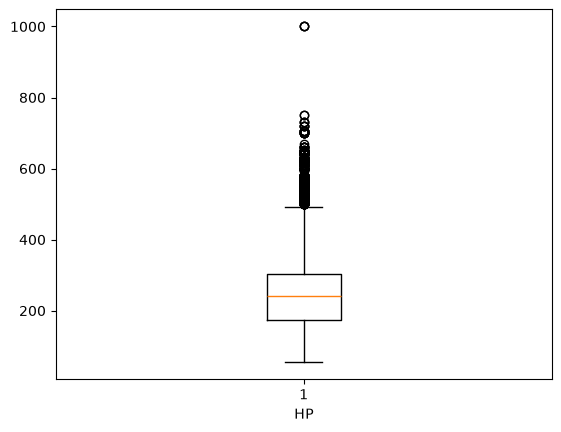

In [24]:
plt.boxplot(df['HP'])
plt.xlabel('HP')
plt.show()

####  Vẽ boxplot cho cột Cylinders

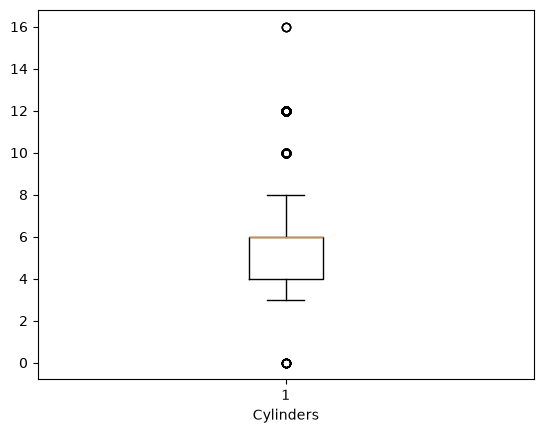

In [25]:
plt.boxplot(df['Cylinders'])
plt.xlabel('Cylinders')
plt.show()

#### Tìm độ trải giữa (IQR) của từng cột dữ liệu

In [26]:
Q1 = df.quantile(0.25, numeric_only=True)
Q3 = df.quantile(0.75, numeric_only=True)

IQR = Q3 - Q1
IQR

Year               9.0
HP               130.0
Cylinders          2.0
Highway MPG        8.0
City MPG           6.0
Price          21327.5
dtype: float64

#### Loại bỏ đi outlier

In [27]:
Q1 = df['Price'].quantile(0.25)
Q3 = df['Price'].quantile(0.75)

IQR = Q3 - Q1
df = df[(df['Price'] >= Q1 - 1.5 * IQR) 
        & (df['Price'] <= Q3 + 1.5 * IQR)]

df.shape

(9891, 10)

#### Câu hỏi ôn tập: Outlier & IQR (Stage 1)

**Câu 1 (Trắc nghiệm):** Một giá trị X của `Price` bị coi là outlier theo IQR (hệ số 1.5) khi:
- A. X < Q1 − 1.5 × IQR hoặc X > Q3 + 1.5 × IQR
- B. Q1 − 1.5 × IQR ≤ X ≤ Q3 + 1.5 × IQR
- C. X < Q1 − 3 × IQR hoặc X > Q3 + 3 × IQR
- D. X > Median + 1.5 × IQR

**Câu 2 (Trắc nghiệm):** Sau khi phát hiện outlier, Stage 1 nêu ba hướng. Câu nào **đúng**?
- A. Chỉ được xóa (drop); clip / winsorize là sai
- B. Có thể xóa, hoặc **clip** (cắt về ngưỡng), hoặc **winsorize** (kéo cực trị vào percentile) — tùy mục tiêu
- C. Winsorize luôn xóa dòng
- D. Clip luôn làm tăng số dòng

**Câu 3 (Tự luận):** Phân biệt **xóa** outlier, **clip**, và **winsorize** (số dòng còn lại đổi thế nào? giá trị cực trị bị thay hay bị bỏ?). Với mục tiêu hiểu **xe phổ thông**, bạn chọn hướng nào cho `Price`? Với mục tiêu mô tả **cả thị trường gồm siêu xe**, chọn hướng nào?

**Câu 4 (Tự luận phản biện):** Xóa theo IQR trên toàn bảng có thể mất Bugatti / Ferrari vì `Price` rất cao. Nên hay không nên? Việc này giúp gì / hại gì nếu sau này chỉ muốn dự đoán giá xe phổ thông?

**Câu 5 (Ôn — làm được):** Tự tính IQR cho các cột số, chỉ ra ngưỡng dưới/trên, và giải thích trước khi xóa: cột nào outlier là lỗi, cột nào outlier là xe thật.

In [28]:
cau_1 = "A"
cau_2 = "B"
cau_3 = """ 
xóa outlier: số dòng giảm, giá trị cực trị bị loại bỏ hoàn toàn
clip: số dòng không đổi, giá trị cực trị được thay bằng ngưỡng dưới hoặc ngưỡng trên
winsorize: số dòng không đổi, giá trị cực trị được kéo về một percentile xác định

- nếu muốn hiểu xe phổ thông: có thể xóa hoặc xử lý outlier để giảm ảnh hưởng của siêu xe
- nếu muốn mô tả cả thị trường gồm siêu xe: nên giữ lại siêu xe hoặc dùng clip/winsorize để không mất dữ liệu thực tế
"""
cau_4 = """ 
không nên xóa máy móc theo IQR vì Bugatti, Ferrari có giá cao nhưng đó có thể là dữ liệu thật
nếu chỉ dự đoán giá xe phổ thông, có thể loại nhóm siêu xe để mô hình tập trung vào phân khúc phổ thông
- lợi ích: giảm ảnh hưởng của giá trị cực cao và giúp mô hình dự đoán xe phổ thông tốt hơn
- tác hại: mất thông tin về phân khúc xe cao cấp và mô hình không còn phù hợp để dự đoán siêu xe
"""
cau_5 = """ 
giải thích:
nếu outlier là do lỗi nhập liệu, sai đơn vị hoặc giá trị không hợp lệ -> có thể xóa
ví dụ: Year = 0 hoặc HP có giá trị bất thường do nhập sai

nếu outlier là dữ liệu thực tế -> không nên xóa máy móc
ví dụ: Price rất cao có thể là Bugatti, Ferrari hoặc các siêu xe khác
HP rất cao cũng có thể là công suất thật của xe thể thao/siêu xe

kết luận: cần kiểm tra nguyên nhân của outlier trước khi quyết định xóa
"""

## 3. Trực quan hóa dữ liệu

**Gợi ý ôn:** biến số → phân phối; biến nhóm → đếm tần suất; hai biến số → scatter; nhiều cột số → heatmap; so sánh phân phối theo nhóm → box/violin. Khi các hãng có **số mẫu khác nhau**, cân nhắc **tỷ lệ** chứ đừng chỉ đếm. Chỉnh tiêu đề, trục, nhiều plot một hình, lưu ảnh — cần kiểm soát figure/axes, không chỉ gọi lệnh vẽ nhanh.

### 3.1. Vẽ histogram cho cột Make

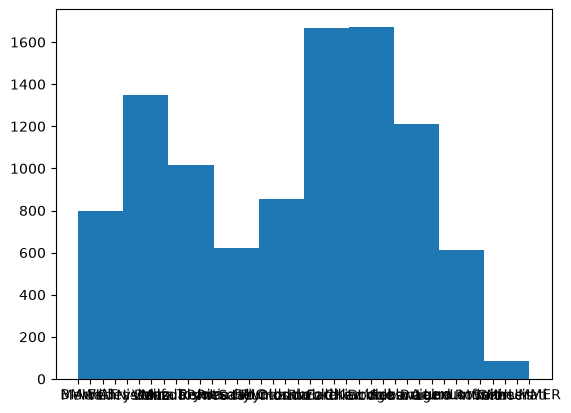

In [29]:
plt.hist(df['Make'])
plt.show()

### 3.2. Vẽ biểu đồ nhiệt

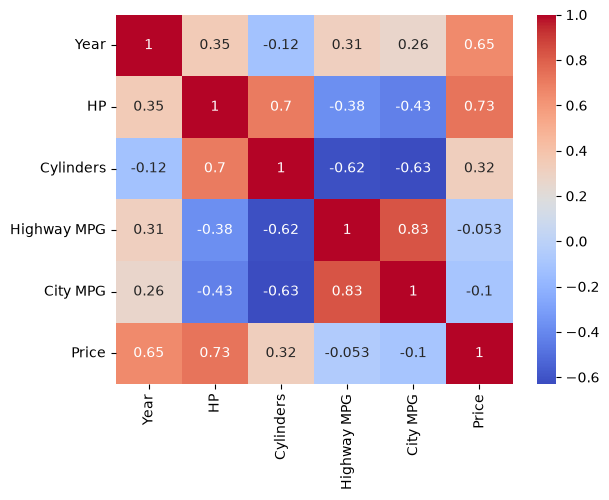

In [30]:
corr = df.corr(numeric_only=True)
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.show()

### 3.3. Vẽ biểu đồ scatter cho Price và HP

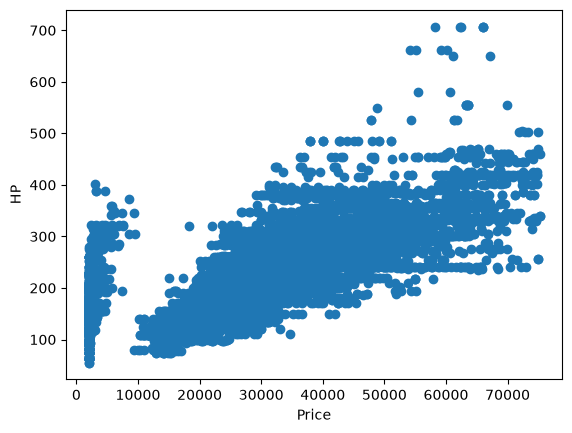

In [31]:
plt.scatter(df['Price'], df['HP'])
plt.xlabel('Price')
plt.ylabel('HP')
plt.show()

#### Câu hỏi ôn tập: EDA 6 bước & trực quan (Stage 1)

**Nhắc:** EDA = mô tả + trực quan để lấy *insight*. Chưa kết luận nhân quả, chưa huấn luyện mô hình.

**Câu 1 (Trắc nghiệm):** Mục tiêu đúng của EDA là gì?
- A. Chứng minh HP **gây ra** giá xe
- B. Mô tả phân phối và quan hệ để hiểu dữ liệu; chưa nhân quả, chưa ML
- C. Chỉ cần đủ để chạy hồi quy là xong
- D. Thay thế toàn bộ kiểm định giả thuyết

**Câu 2 (Trắc nghiệm):** `Make` là biến **phân loại** (hãng xe). Biểu đồ nào **phù hợp hơn** để xem tần suất từng hãng?
- A. Histogram (dành phân phối biến số)
- B. Biểu đồ đếm theo nhóm (bar / countplot)
- C. Heatmap tương quan
- D. Scatter `Price` vs `HP`

**Câu 3 (Tự luận):** Chevrolet có **nhiều dòng** hơn Alfa Romeo. Nếu chỉ soánh **số lượng** xe đắt theo hãng, kết luận có thể lệch ở đâu? Vì sao khi cỡ mẫu khác nhau nên nhìn **tỷ lệ (rate)** thay vì chỉ **count**?

**Câu 4 (Tự luận — làm được):** Với tập xe, bạn chọn loại biểu đồ nào cho từng nhu cầu? Viết 1 câu / nhu cầu, **không cần dán code**:
- phân phối `Price` hoặc `HP`
- tần suất `Transmission` hoặc `Make`
- quan hệ hai biến số `HP` và `Price`
- tương quan nhiều cột số (heatmap)
- so sánh phân phối giá theo nhóm (box / violin)

**Câu 5 (Trắc nghiệm — đúng/sai, chọn câu sai):** Về Matplotlib / Seaborn, câu **SAI** là:
- A. Seaborn vẽ nhanh từ DataFrame; vẫn dùng Matplotlib để chỉnh title, trục, layout, lưu ảnh
- B. Có hai kiểu viết: gọi trực tiếp `plt...` hoặc dùng `fig, ax = ...` (object-oriented)
- C. Seaborn **thay thế hoàn toàn** Matplotlib, không cần học `ax` / `plt` nữa
- D. Tô màu theo nhóm dùng `hue`; nhiều plot một figure dùng subplots

**Câu 6 (Tự luận ngắn — feature engineering):** Đề xuất **một** biến mới từ `Year`, **một** cách chia nhóm (bin) cho `HP` hoặc `Price`, và nêu vì sao biến phân loại như `Transmission` thường cần mã hóa (dummy) **nếu** sau này đưa vào mô hình. EDA bước này chưa bắt buộc scale — vì sao vẫn nên *biết* scaling là gì?

**Câu 7 (Tổng kết — làm được):** Viết **3 insight** từ biểu đồ (ví dụ: giá lệch, HP đi kèm giá, hãng nào chiếm nhiều mẫu…) và **1 caveat** (giới hạn: outlier siêu xe, dữ liệu cũ, hãng lệch số lượng, EDA không suy nhân quả).

In [32]:
cau_1 = "B"
cau_2 = "B"
cau_3 = """ 
nếu Chevrolet có nhiều dòng xe hơn Alfa Romeo thì Chevrolet có thể có nhiều xe đắt hơn
chỉ nhìn số lượng (count) có thể gây hiểu lầm vì kích thước mẫu của hai hãng khác nhau
nên xem tỷ lệ (rate) xe đắt trên tổng số xe của từng hãng
tỷ lệ giúp so sánh công bằng hơn giữa các nhóm có số lượng mẫu khác nhau
"""
cau_4 = """ 
phân phối Price hoặc HP -> dùng histogram để xem phân phối dữ liệu
tần suất Transmission hoặc Make -> dùng bar chart hoặc countplot
quan hệ HP và Price -> dùng scatter plot
tương quan nhiều cột số -> dùng heatmap
so sánh phân phối giá theo nhóm -> dùng boxplot hoặc violin plot
"""
cau_5 = "c"
cau_6 = """ 
có thể tạo biến Vehicle_Age = năm hiện tại - Year
có thể chia HP thành các nhóm: thấp, trung bình, cao
Transmission là biến phân loại nên thường cần mã hóa thành các biến số như dummy
để mô hình có thể xử lý dữ liệu phân loại
EDA chưa bắt buộc scale nhưng nên biết scaling vì một số mô hình nhạy cảm với sự khác nhau về thang đo
"""
cau_7 = """ 
insight 1: Price có thể phân phối lệch phải do một số xe có giá rất cao
insight 2: xe có HP cao thường có xu hướng có Price cao hơn
insight 3: một số hãng có số lượng xe trong dữ liệu nhiều hơn các hãng khác
caveat: outlier như siêu xe có thể ảnh hưởng kết quả và số lượng mẫu giữa các hãng không đồng đều
ngoài ra EDA chỉ cho thấy mối quan hệ, không thể kết luận quan hệ nhân quả
"""

#BÀI TOÁN KIỂM ĐỊNH
1. CHO 1 BÀI TOÁN KIỂM ĐỊNH T-TEST
2. CHO 1 BÀI TOÁN KIỂM ĐỊNH Z-TEST
3. CHO 1 BÀI TOÁN KIỂM ĐỊNH CHI-SQUARE
4. CHO 1 BÀI TOÁN KIỂM ĐỊNH ANOVA

In [33]:
# 1. Bài toán kiểm định T-Test
# Câu hỏi nghiên cứu: Liệu giá cả trung bình của các xe có động cơ 6 xi lanh có khác biệt đáng kể so với giá cả trung bình của các xe có động cơ 4 xi lanh không?

# Giả thuyết null (H0): Giá cả trung bình của xe 6 xi lanh bằng giá cả trung bình của xe 4 xi lanh.
# Giả thuyết đối (H1): Giá cả trung bình của xe 6 xi lanh khác với giá cả trung bình của xe 4 xi lanh.

from scipy import stats

# Lọc dữ liệu cho xe có động cơ 4 và 6 xi lanh
cars_4_cylinders = df[df['Cylinders'] == 4]['Price']
cars_6_cylinders = df[df['Cylinders'] == 6]['Price']

# Thực hiện kiểm định T-Test
t_statistic, p_value = stats.ttest_ind(cars_4_cylinders, cars_6_cylinders)

# In kết quả
print(f"T-Statistic: {t_statistic}")
print(f"P-Value: {p_value}")

# Quyết định về giả thuyết
alpha = 0.05  # Mức ý nghĩa
if p_value < alpha:
    print("Bác bỏ H0: Giá cả trung bình của xe 6 xi lanh khác với xe 4 xi lanh.")
else:
    print("Không bác bỏ H0: Giá cả trung bình của xe 6 xi lanh bằng với xe 4 xi lanh.")

T-Statistic: -27.460888867589222
P-Value: 5.738512830927822e-159
Bác bỏ H0: Giá cả trung bình của xe 6 xi lanh khác với xe 4 xi lanh.


In [34]:
# 2. Bài toán kiểm định Z-Test
# Câu hỏi nghiên cứu: Liệu giá trung bình của xe trong mẫu có khác biệt đáng kể so với mức giá trung bình đã biết của toàn bộ xe trên thị trường (giả sử là 30,000 USD)?

# Giả thuyết null (H0): Giá trung bình của xe trong mẫu bằng 30,000 USD.
# Giả thuyết đối (H1): Giá trung bình của xe trong mẫu khác với 30,000 USD.

# Lấy giá cả của xe trong mẫu
sample_prices = df['Price']

# Tính toán các thông số cần thiết
sample_mean = np.mean(sample_prices)
sample_std = np.std(sample_prices, ddof=1)  # ddof=1 để tính độ lệch chuẩn mẫu
n = len(sample_prices)
known_mean = 30000  # Giá trung bình đã biết

# Tính giá trị Z
z_value = (sample_mean - known_mean) / (sample_std / np.sqrt(n))

# Tính giá trị p từ giá trị Z
p_value = 2 * (1 - stats.norm.cdf(abs(z_value)))  # Nhân đôi để kiểm định hai phía

# In kết quả
print(f"Z-Value: {z_value}")
print(f"P-Value: {p_value}")

# Quyết định về giả thuyết
alpha = 0.05  # Mức ý nghĩa
if p_value < alpha:
    print("Bác bỏ H0: Giá trung bình của xe trong mẫu khác với 30,000 USD.")
else:
    print("Không bác bỏ H0: Giá trung bình của xe trong mẫu bằng 30,000 USD.")

Z-Value: -0.9806677970179407
P-Value: 0.3267565892368358
Không bác bỏ H0: Giá trung bình của xe trong mẫu bằng 30,000 USD.


In [35]:
# 3. Bài toán kiểm định Chi-Square
# Câu hỏi nghiên cứu: Có sự liên quan nào giữa loại xe (Make) và kiểu truyền động (Transmission Type) không?

# Giả thuyết null (H0): Không có sự liên quan giữa loại xe và kiểu truyền động.
# Giả thuyết đối (H1): Có sự liên quan giữa loại xe và kiểu truyền động.

# Tạo bảng tần số cho loại xe và kiểu truyền động
contingency_table = pd.crosstab(df['Make'], df['Transmission'])

# In bảng tần số
print("Bảng tần số:")
print(contingency_table)

# Thực hiện kiểm định Chi-Square
chi2_statistic, p_value, dof, expected = stats.chi2_contingency(contingency_table)

# In kết quả
print(f"\nChi-Square Statistic: {chi2_statistic}")
print(f"P-Value: {p_value}")
print(f"Degrees of Freedom: {dof}")
print(f"Expected Frequencies:\n{expected}")

# Quyết định về giả thuyết
alpha = 0.05  # Mức ý nghĩa
if p_value < alpha:
    print("Bác bỏ H0: Có sự liên quan giữa loại xe và kiểu truyền động.")
else:
    print("Không bác bỏ H0: Không có sự liên quan giữa loại xe và kiểu truyền động.")

Bảng tần số:
Transmission   AUTOMATED_MANUAL  AUTOMATIC  DIRECT_DRIVE  MANUAL  UNKNOWN
Make                                                                     
Acura                        20        167             0      54        0
Alfa Romeo                    5          0             0       0        0
Audi                         98        126             0      47        0
BMW                           5        169             4      53        0
Buick                         0        184             0       0        0
Cadillac                      0        303             0      11        0
Chevrolet                     0        711             8     305        0
Chrysler                      0        167             0      16        2
Dodge                         0        332             0     165        1
FIAT                          0         22             0      36        0
Ford                         11        578             0     207        0
GMC                      

In [36]:
# 4. Bài toán kiểm định ANOVA
# Câu hỏi nghiên cứu: Liệu giá cả trung bình của các xe có sự khác biệt giữa các loại động cơ (ví dụ: động cơ 4, 6 và 8 xi lanh) không?

# Giả thuyết null (H0): Giá cả trung bình của xe giữa các loại động cơ là như nhau.
# Giả thuyết đối (H1): Ít nhất một trong các giá trị giá cả trung bình giữa các loại động cơ là khác nhau.

# Nhóm giá cả xe theo từng loại động cơ
grouped_data = [group['Price'].values for name, group in df.groupby('Cylinders')]

# Thực hiện kiểm định ANOVA
f_statistic, p_value = stats.f_oneway(*grouped_data)

# In kết quả
print(f"F-Statistic: {f_statistic}")
print(f"P-Value: {p_value}")

# Quyết định về giả thuyết
alpha = 0.05  # Mức ý nghĩa
if p_value < alpha:
    print("Bác bỏ H0: Có sự khác biệt giữa giá cả trung bình của các loại động cơ.")
else:
    print("Không bác bỏ H0: Giá cả trung bình của xe giữa các loại động cơ là như nhau.")

F-Statistic: 192.99544514485004
P-Value: 2.8091935077714657e-269
Bác bỏ H0: Có sự khác biệt giữa giá cả trung bình của các loại động cơ.
